# SHOWING 1) LIOUVILLE THEOREM 2) CANONICAL TRANSFORMATIONS KEEP VOLUME INVARIANT

In [1]:
from matplotlib import pyplot as plt
import numpy as np

## Declare Non-Linear Pendulums and Time Evolve

In [74]:
g  = 9.8
L = 9.8
w = np.sqrt(g/L)
m = 1.

class pendulum(): #no damping or driving
    def __init__(self, m, w, L, th0, p0, tmax):
        #natural frequency which can never change
        self.w = w
        self.mass = m
        self.L = L
        self.t = np.linspace(0., tmax, int(tmax/0.001 + 1))
        self.dt = self.t[1] - self.t[0]
    
        #initial parameters
        self.th = np.zeros(len(self.t))
        self.th[0] = th0

        self.p = np.zeros(len(self.t))
        self.p[0] = p0

        self.x = self.L*np.sin(self.th)
        self.y = self.L*(1. - np.cos(self.th))
        self.E = (1.0/(2.0*m*L**2.))*self.p**2. + self.mass*g*self.y

        self.Q = np.zeros(len(self.t))
        self.P = np.zeros(len(self.t))

    def a(self,th,p):
        return -m*g*L*np.sin(th), p/(m*L**2.)
    
    def RK4(self, th, p, t):
        a_unwrap = self.a(th, p)
        pk1, thk1 = self.dt*a_unwrap[0], self.dt*a_unwrap[1]

        pd = p + pk1/2.0
        thd = th + thk1/2.0
        td = t + self.dt/2.0

        a_unwrap = self.a(thd, pd)
        pk2, thk2 = self.dt*a_unwrap[0], self.dt*a_unwrap[1]

        pd = p + pk2/2.0
        thd = th + thk2/2.0
        td = t + self.dt/2.0

        a_unwrap = self.a(thd, pd)
        pk3, thk3 = self.dt*a_unwrap[0], self.dt*a_unwrap[1]
    
        pd = p + pk3
        thd = th + thk3
        td = t + self.dt

        a_unwrap = self.a(thd, pd)
        pk4, thk4 = self.dt*a_unwrap[0], self.dt*a_unwrap[1]
            
        new_th = th + (1.0/6.0)*(thk1 + 2.0*thk2 + 2.0*thk3 + thk4)
        if new_th>np.pi:
            new_th = new_th - 2*np.pi
        elif new_th<-np.pi:
            new_th = new_th + 2*np.pi

        return p + (1.0/6.0)*(pk1 + 2.0*pk2 + 2.0*pk3 + pk4), new_th
    
    def TE(self):
        for i in range(0, len(self.t)-1):
            self.p[i+1], self.th[i+1] = self.RK4(self.th[i], self.p[i], self.t[i])

        self.x = L*np.sin(self.th)
        self.y = self.L*(1. - np.cos(self.th))
        self.E = (1.0/(2.0*m*L**2.))*self.p**2. + self.mass*g*self.y

    def canonical_transform(self):
        self.Q = np.unwrap( np.arctan2(self.w*self.th*self.mass*self.L**2.,self.p) )
        self.P = (self.p**2. +self.w**2.*self.th**2.*self.mass**2.*self.L**4.)/(2*self.w*self.mass*self.L**2.)

In [75]:
# --- cell 4 replacement: 2D blob of initial conditions ---
p_scale = m * L**2 * w          # natural momentum unit (~96 here) to de-skew the blob

th_c, p_c = 1.2, 0.0            # blob center: amplitude ~1.2 rad -> visibly nonlinear, librates
R         = 0.5                 # blob radius in scaled coords

# ORDERED boundary ellipse (for exact area via shoelace on the mapped boundary)
N_bd = 400
phi  = np.linspace(0, 2*np.pi, N_bd, endpoint=False)
th0s = th_c + R*np.cos(phi)
p0s  = p_c  + R*p_scale*np.sin(phi)

pendus = [pendulum(m, w, L, th0s[i], p0s[i], 6*2*np.pi) for i in range(N_bd)]

In [76]:
for i in range(0, len(pendus)):
    pendus[i].TE()
    pendus[i].canonical_transform()

## Verify Liouville Theorem and Canonical Transform

In [116]:
def enclosed_area(th, p): #shoelace formula
    return 0.5*np.abs(np.sum(th*np.roll(p,-1) - np.roll(th,-1)*p))

In [117]:
# area vs time over the whole run
areas_p_q = np.array([enclosed_area(np.array([pen.th[i] for pen in pendus]), 
                          np.array([pen.p[i] for pen in pendus]) ) for i in range(len(pendus[0].t))])

In [118]:
areas_P_Q = np.array([enclosed_area(np.array([pen.Q[i] for pen in pendus]), 
                          np.array([pen.P[i] for pen in pendus]) ) for i in range(len(pendus[0].t))])

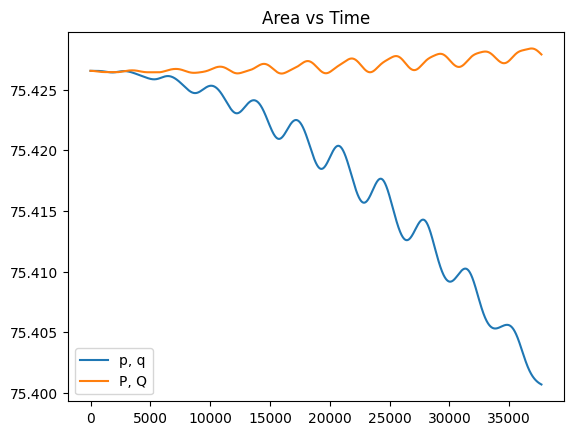

In [119]:
plt.plot(areas_p_q, label ='p, q')
plt.plot(areas_P_Q, label ='P, Q')
plt.title('Area vs Time')
plt.legend()
plt.show()

## Visualize

In [204]:
def plot_frame(index, top, p_q, P_Q):

   
    #read in data

    Q = np.array([pen.Q[index] for pen in pendus])
    P = np.array([pen.P[index] for pen in pendus])

    q = np.array([pen.th[index] for pen in pendus])
    p = np.array([pen.p[index] for pen in pendus])

    x = np.array([pen.x[index] for pen in pendus])
    y = np.array([pen.y[index] for pen in pendus])


    #pendulum plots

    #top.scatter([x[0], x[99], x[199], x[299], x[399]],[y[0], y[99], y[199], y[299], y[399]], c='red', s= 1 )
    top.scatter(x,y, c='red', s= 1 )
    for i in range(0, len(pendus)):
        top.plot([0, x[i]],[L, y[i]], c='white', linewidth = 1)
    top.set_xlim([-1.1*L,1.1*L])
    top.set_ylim([0-0.1*L, 1.1*L])

    for spine in top.spines.values():
            spine.set_color('white')
            spine.set_linewidth(1.5)
    
    #phase space plots
    
    p_q.fill(q, p, facecolor='yellow', alpha=1, edgecolor='red')
    P_Q.fill(Q, P, facecolor='yellow', alpha=1, edgecolor='red')

    p_q.annotate(f'Area: {areas_p_q[index]:.3f}', ((np.max(q) +np.min(q))/2,(np.max(p) +np.min(p))/2), c='red', fontsize=15)
    P_Q.annotate(f'Area: {areas_P_Q[index]:.3f}', ((np.max(Q) +np.min(Q))/2,(np.max(P) +np.min(P))/2), c='red', fontsize=15)
          
    p_q.set_xlabel(r'$\theta$', fontsize=15, c='white')
    p_q.set_ylabel(r'$p_\theta$', fontsize=15, c='white')
    p_q.tick_params(colors='white')
    p_q.set_xticks([])
    p_q.set_yticks([])
    for spine in p_q.spines.values():
        spine.set_color('white')
        spine.set_linewidth(1.5)
      
    P_Q.set_xlabel(r'$Q = tan^{-1}(\omega \theta m L^2/p_\theta)$', fontsize=15, c='white')
    P_Q.set_ylabel(r'$P = (p^2 + \omega^2 \theta^2 m^2 L^4)/(2 \omega m L^2)$', fontsize=15, c='white')
    P_Q.tick_params(colors='white')
    P_Q.set_xticks([])
    P_Q.set_yticks([])

    for spine in P_Q.spines.values():
        spine.set_color('white')
        spine.set_linewidth(1.5)

   
  

In [78]:
len(pendus[0].t)

37700

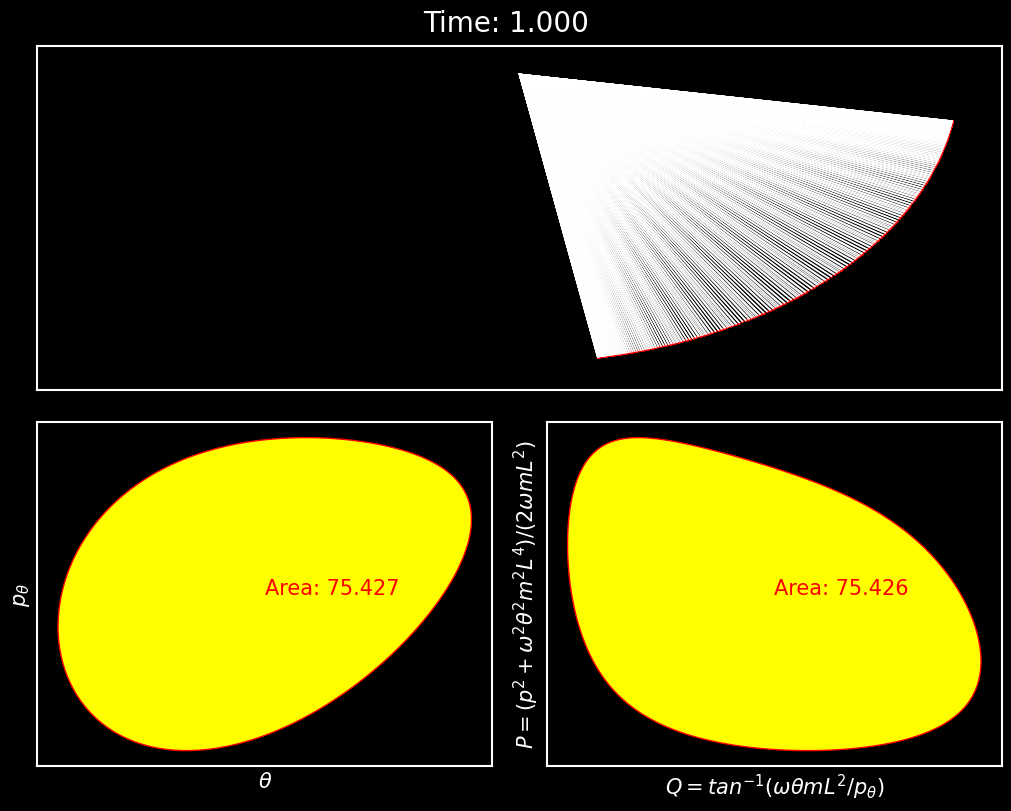

In [205]:
fig = plt.figure(figsize=(10, 8), constrained_layout=True)
gs  = fig.add_gridspec(2, 2)
top = fig.add_subplot(gs[0, :])     # row 0, both columns
p_q = fig.add_subplot(gs[1, 0])     # row 1, col 0
P_Q = fig.add_subplot(gs[1, 1])     # row 1, col 1


fig.suptitle('Time: '+str("%.3f" %(pendus[0].t[1000])), c='white', fontsize =20)
fig.patch.set_facecolor('black')
top.set_facecolor('black')
p_q.set_facecolor('black')
P_Q.set_facecolor('black')
plot_frame(1000,top, p_q, P_Q)
plt.show()

## Make Movie

In [176]:
from matplotlib.animation import PillowWriter

In [177]:
metadata = dict(title='Movie', artist ='ayush_roy')
writer = PillowWriter(fps=10, metadata = metadata)

In [189]:
len(pendus[0].t)/150

251.33333333333334

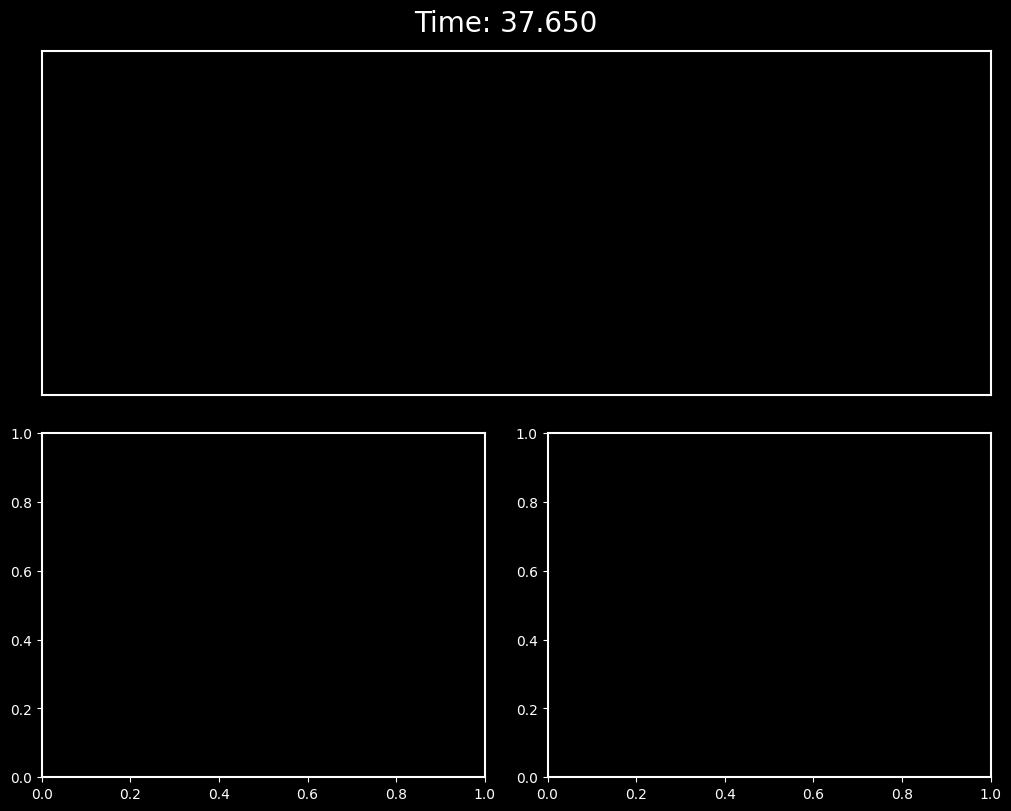

In [206]:
fig = plt.figure(figsize=(10, 8), constrained_layout=True)
gs  = fig.add_gridspec(2, 2)
top = fig.add_subplot(gs[0, :])     # row 0, both columns
p_q = fig.add_subplot(gs[1, 0])     # row 1, col 0
P_Q = fig.add_subplot(gs[1, 1])     # row 1, col 1

fig.patch.set_facecolor('black')
top.set_facecolor('black')
p_q.set_facecolor('black')
P_Q.set_facecolor('black')


with writer.saving(fig, 'single_pendulum_hamilton_jacobi.gif',100):
    for i in range(0, len(pendus[0].t)):
        if i%150 == 0:
            fig.suptitle('Time: '+str("%.3f" %(pendus[0].t[i])), c='white', fontsize =20)
            plot_frame(i,top, p_q, P_Q)
            writer.grab_frame()
            top.clear()
            p_q.clear()
            P_Q.clear()